# Figure 1, panels b–d — regulators and gene programs during arterial endothelial differentiation

This notebook reproduces computational panels **b–d**. Panel a is an experimental schematic and is not generated here.

- **Panel b:** genome-wide CRISPRi screen volcano plot using U-test log2 fold changes and directional MAGeCK FDR values.
- **Panel c:** guide-level Day 3 endothelial differentiation estimates from the validation screen, with two-sided Welch tests and BH correction across target genes.
- **Panel d:** integrated UMAP colored by the dominant selected cNMF program.

Input locations are specified in `config/paths.example.yaml` and may be overridden in `config/paths.local.yaml`.


In [1]:
# Repository-path bootstrap for local support modules.
from pathlib import Path
import sys


def _find_repo_root(start=None):
    start = Path(start or Path.cwd()).resolve()
    for candidate in (start, *start.parents):
        if (candidate / "src" / "cc_perturbseq").is_dir():
            return candidate
    raise FileNotFoundError(
        "Could not locate the repository root containing "
        "src/cc_perturbseq. Run this notebook from within the "
        "cc-perturbseq-manuscript-analysis checkout."
    )


REPO_ROOT = _find_repo_root()
for _support_path in (REPO_ROOT, REPO_ROOT / "src"):
    _support_path_text = str(_support_path)
    if _support_path_text not in sys.path:
        sys.path.insert(0, _support_path_text)

print(
    "Repository support paths added:",
    REPO_ROOT,
    "and",
    REPO_ROOT / "src",
)


Repository support paths added: /oak/stanford/groups/engreitz/Users/tri/CodeBase/cc-perturbseq-figure-reproduction and /oak/stanford/groups/engreitz/Users/tri/CodeBase/cc-perturbseq-figure-reproduction/src


In [2]:
from __future__ import annotations

from pathlib import Path
from IPython.display import display

from src.cc_perturbseq.figure_notebook import (
    get_path, initialize_figure, load_figure_manifest, panel_directory, sha256_file, write_receipt,
)
from src.cc_perturbseq.figure1_plotnine import (
    PANEL_C_GROUPS,
    make_figure_01b_plotnine,
    run_figure_01c_plotnine,
    save_plotnine_panel,
)
from src.cc_perturbseq.figure1_panel_d import make_figure_01d


def save_matplotlib_figure(
    fig,
    outdir: Path,
    stem: str,
    *,
    png_dpi: int = 300,
    pad_inches: float = 0.02,
):
    outputs = {}
    for suffix in ("pdf", "svg", "png"):
        path = outdir / f"{stem}.{suffix}"
        fig.savefig(
            path,
            dpi=png_dpi if suffix == "png" else None,
            bbox_inches="tight",
            pad_inches=pad_inches,
            facecolor="white",
        )
        outputs[suffix] = str(path)
    return outputs


FIGURE = load_figure_manifest("Figure_01")
FIGURE["panels"] = [panel for panel in FIGURE["panels"] if panel["panel"] in {"b", "c", "d"}]
for panel in FIGURE["panels"]:
    if panel["panel"] == "c":
        panel["required_inputs"] = ["screen.validation_guide_counts"]
FIGURE["scope"] = "Panels b–d"
ctx = initialize_figure(FIGURE)
ctx["input_audit"]


/oak/stanford/groups/engreitz/Users/tri/CodeBase/cc-perturbseq-figure-reproduction/src/cc_perturbseq/figure_notebook.py:282: RuntimeWarning: config/paths.local.yaml is absent; using the tracked Sherlock defaults in config/paths.example.yaml. Create paths.local.yaml only for machine-specific overrides.


,key,path,exists,is_file,is_dir,size_bytes,error
0,ccperturbseq.cnmf_usage,/oak/stanford/groups/engreitz/Users/ymo/IGVF_c...,True,True,False,51382087,None
1,ccperturbseq.integrated_anndata,/oak/stanford/groups/engreitz/Users/opushkar/c...,True,True,False,4218513308,None
2,ccperturbseq.program_annotations,/oak/stanford/groups/engreitz/Users/tri/CodeBa...,True,True,False,9911,None
3,screen.genomewide_mageck_pos_vs_neg,/oak/stanford/groups/engreitz/Users/dulguun/23...,True,True,False,1928870,None
4,screen.genomewide_utest_pos_vs_neg,/oak/stanford/groups/engreitz/Users/dulguun/23...,True,True,False,1468414,None
5,screen.validation_guide_counts,/oak/stanford/groups/engreitz/Users/chloemc/Ge...,True,True,False,135257,None


## Panel b — genome-wide CRISPRi screen

The x axis is the U-test log2 fold change. The y axis uses the directional MAGeCK FDR: `neg|fdr` for negative effects and `pos|fdr` for positive effects. A gene is classified as a MAGeCK hit when either directional FDR is below 0.05. The panel is rendered with plotnine and exported as vector and raster graphics.


findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberati

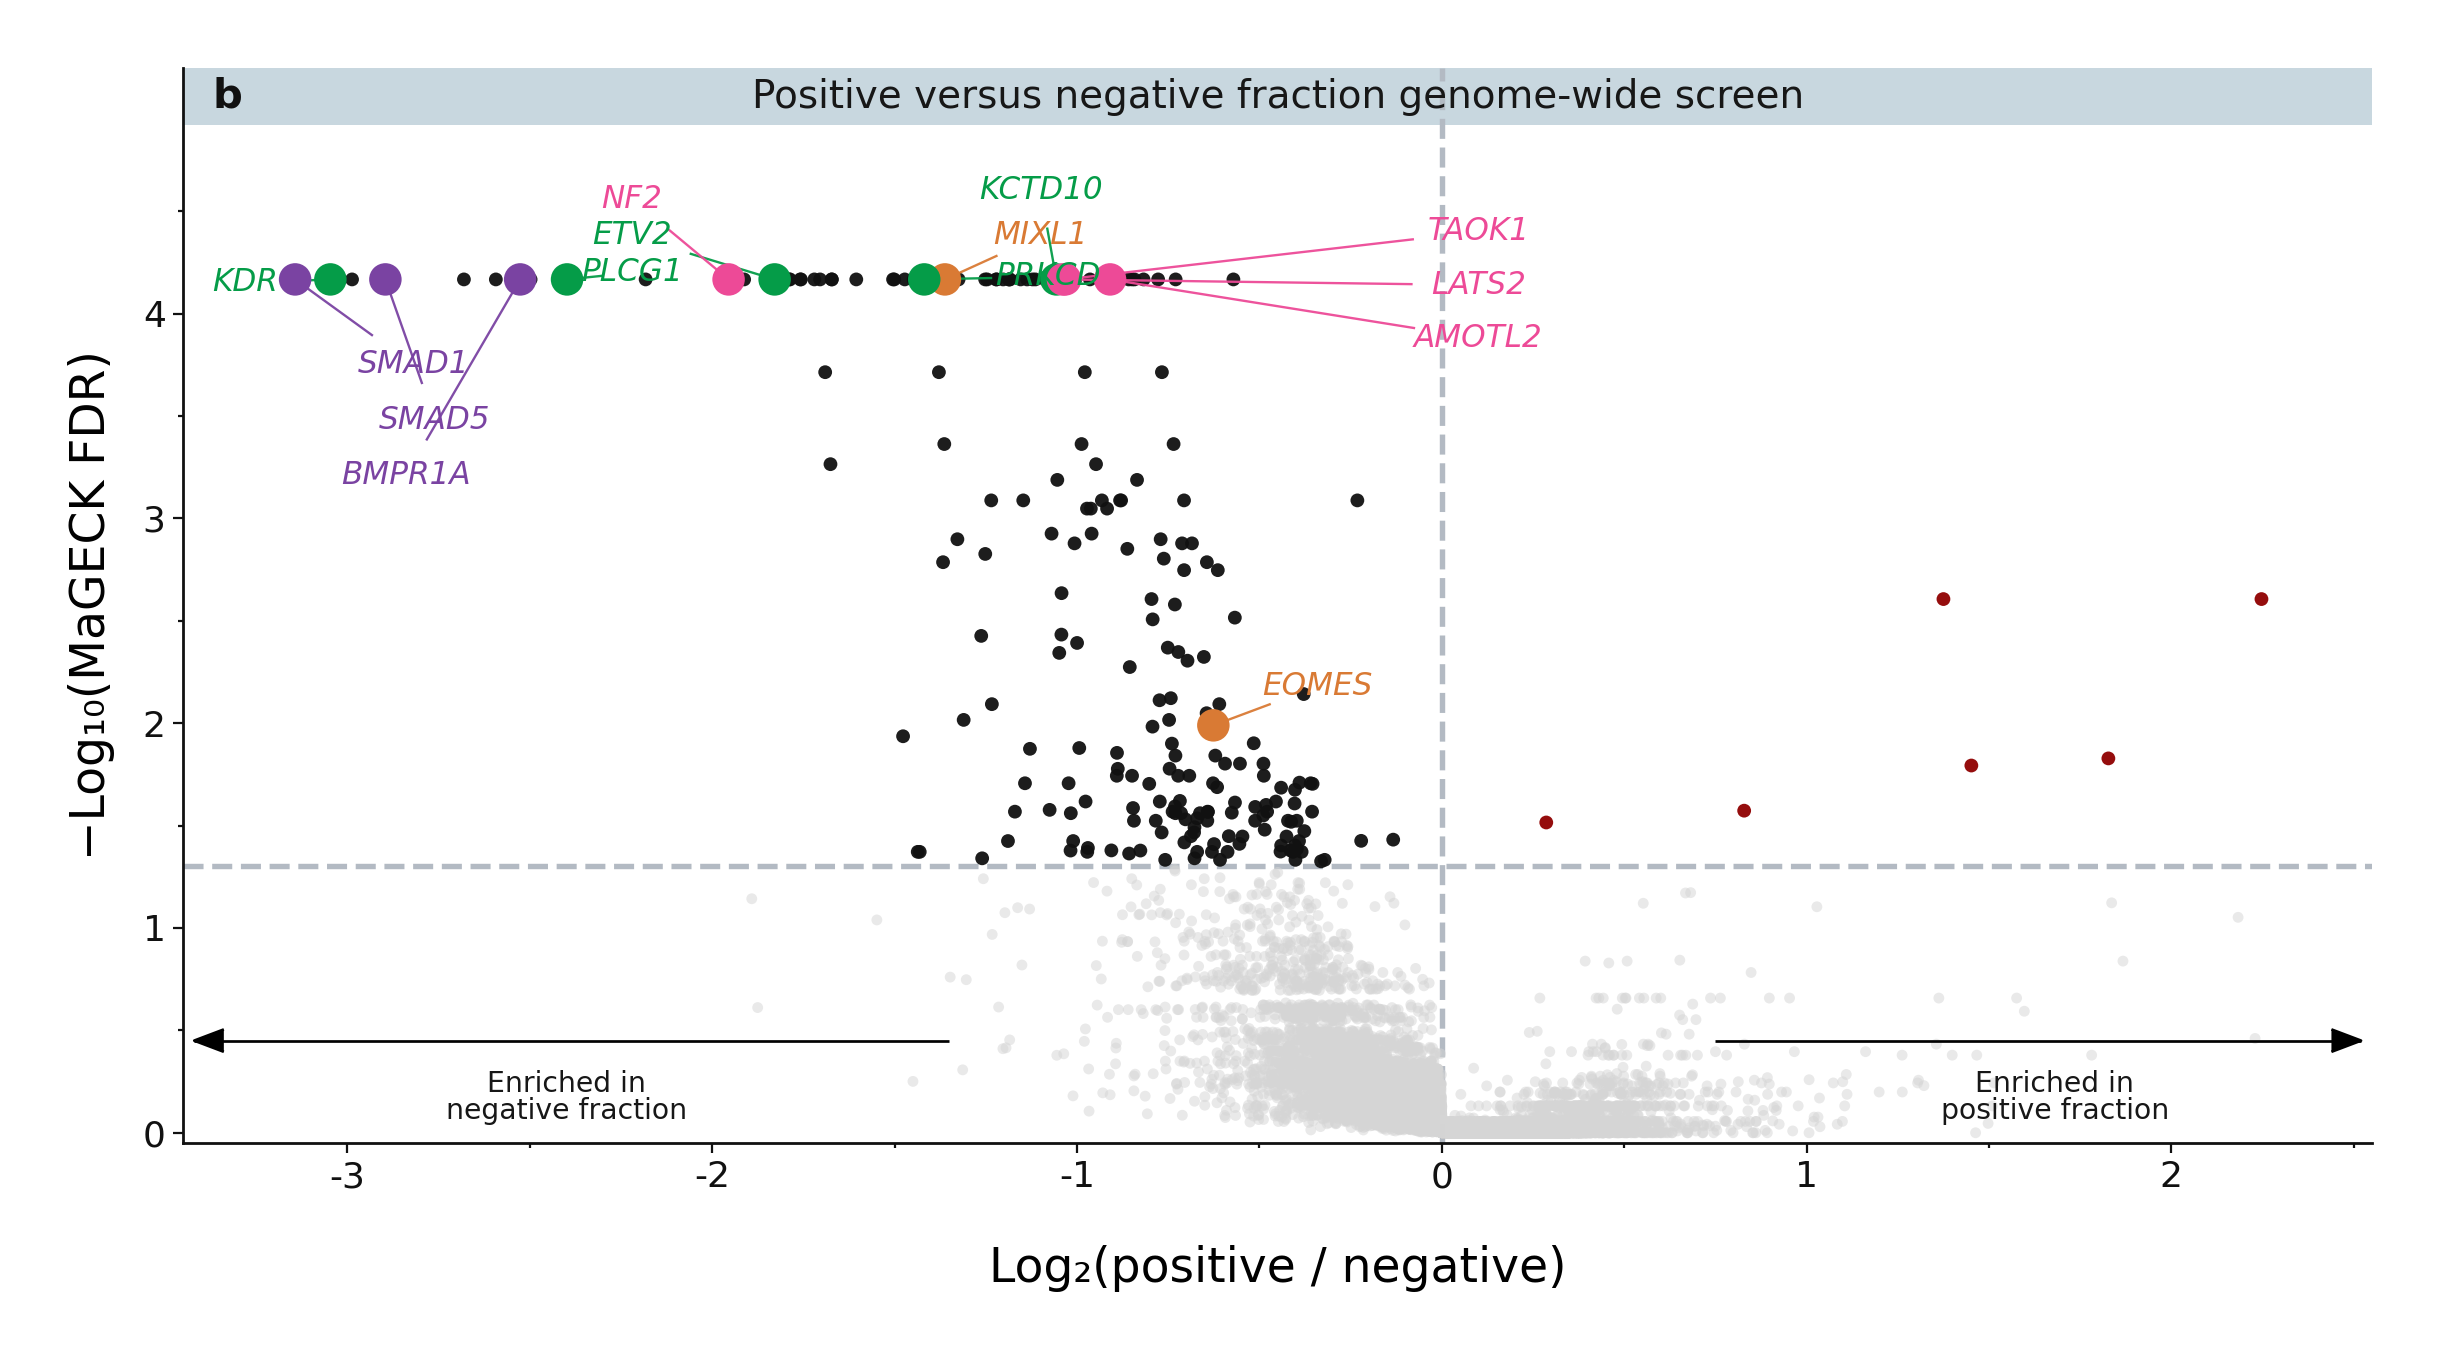

In [3]:
mageck_path = get_path(ctx["paths"], "screen.genomewide_mageck_pos_vs_neg")
utest_path = get_path(ctx["paths"], "screen.genomewide_utest_pos_vs_neg")
plot_b, source_b, labels_b = make_figure_01b_plotnine(mageck_path, utest_path)
out_b = panel_directory(ctx, "b")
outputs_b = save_plotnine_panel(
    plot_b,
    out_b,
    "Figure_01b_genomewide_screen_volcano",
    png_dpi=600,
)
source_b.to_csv(out_b / "Figure_01b_source_data.csv", index=False)
labels_b.to_csv(out_b / "Figure_01b_label_positions.csv", index=False)
write_receipt(
    ctx,
    "b",
    status="SOURCE_VERIFIED_IMPLEMENTATION",
    inputs={
        "mageck": str(mageck_path),
        "mageck_sha256": sha256_file(mageck_path),
        "utest": str(utest_path),
        "utest_sha256": sha256_file(utest_path),
    },
    outputs={**outputs_b, "source_data": str(out_b / "Figure_01b_source_data.csv")},
    parameters={
        "source_script": "Pos_vs_Neg_volcano_plotnine_MAGECK_FDR_pathway_colored_v8.py",
        "x_axis": "U-test log2FC",
        "y_axis": "directional MAGeCK FDR",
        "fdr_cutoff": 0.05,
        "vertical_reference": 0.0,
        "plotting_backend": "plotnine",
        "post_draw_matplotlib_editing": False,
    },
)
display(plot_b)


## Panel c — validation-screen guide-level Day 3 EC fractions

Guide counts from two CDH5-positive and two CDH5-negative samples are used to estimate endothelial differentiation for each guide. For each biological replicate, a 0.5-count pseudocount is added and the positive/negative count ratio is converted to log2 odds. The replicate-specific odds are centered so that the arithmetic mean EC percentage across the 120 control guides is 70%. The two replicate-specific percentages are then averaged for each guide. Each target gene is compared with the 120 controls using a **two-sided Welch t-test**, followed by BH correction across all 297 target genes.

The guide-level distributions, deterministic point positions, significance labels, and pathway groupings are rendered with plotnine.


findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberati

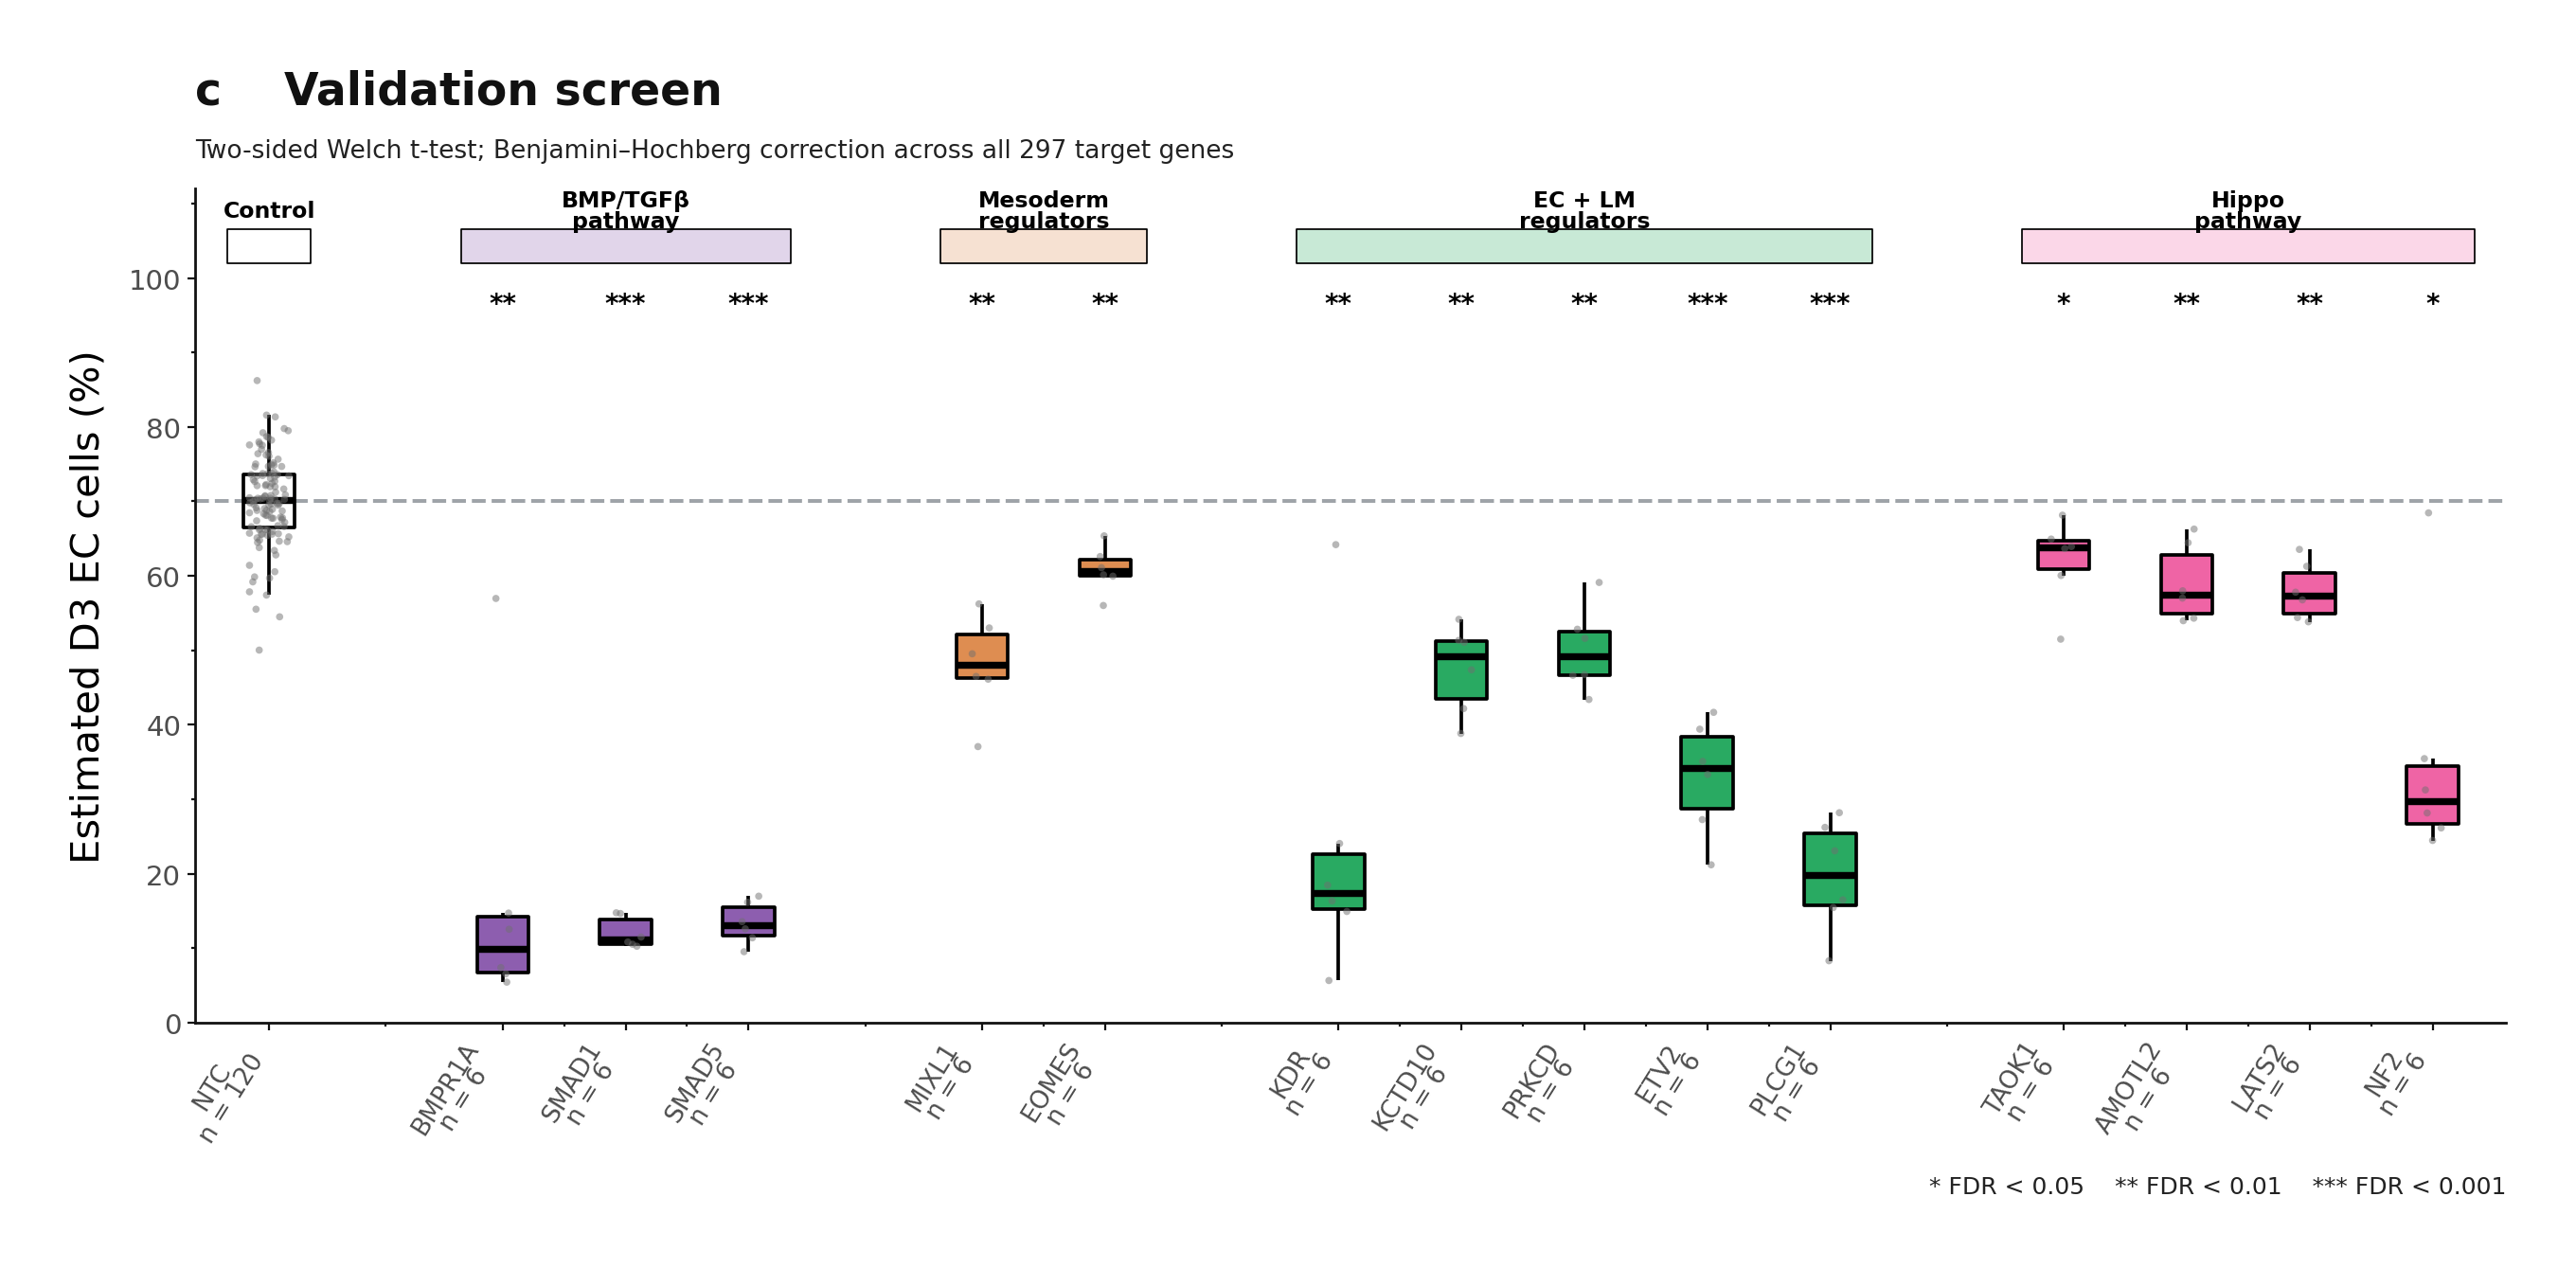

,gene,n_targeting_guides,mean_target_EC_pct,welch_pvalue_two_sided,FDR_BH,significance
0,BMPR1A,6,17.260268,1.231258e-03,5.223216e-03,**
1,SMAD1,6,12.078923,1.086213e-13,3.226051e-11,***
2,SMAD5,6,13.361880,3.342014e-10,1.985156e-08,***
3,MIXL1,6,48.071927,3.576148e-04,2.124232e-03,**
4,EOMES,6,60.857545,3.047581e-04,1.925812e-03,**
5,KDR,6,23.931194,2.724868e-03,9.196430e-03,**
6,KCTD10,6,47.489787,1.619224e-04,1.202274e-03,**
7,PRKCD,6,50.051463,2.265704e-04,1.623819e-03,**
8,ETV2,6,32.986413,5.575688e-05,5.869317e-04,***
9,PLCG1,6,19.616154,1.032734e-05,1.879131e-04,***


In [4]:
validation_counts_path = get_path(ctx["paths"], "screen.validation_guide_counts")
out_c = panel_directory(ctx, "c")
(
    plot_c,
    stats_c,
    selected_stats_c,
    guide_table_c,
    outputs_c,
    validation_counts_hash,
    calibration_offsets_c,
) = run_figure_01c_plotnine(
    validation_counts_path,
    out_c,
    control_baseline_pct=70.0,
    pseudocount=0.5,
)
write_receipt(
    ctx,
    "c",
    status="SOURCE_VERIFIED_RECALCULATION",
    inputs={
        "validation_guide_counts": str(validation_counts_path),
        "sha256": validation_counts_hash,
    },
    outputs=outputs_c,
    parameters={
        "source": "Chloe McCreery validation-screen MAGeCK guide-count table",
        "positive_columns": ["D3PR1", "D3PR2"],
        "negative_columns": ["D3NR1", "D3NR2"],
        "count_pseudocount": 0.5,
        "control_baseline_pct": 70.0,
        "calibration": "replicate-specific offset chosen so mean of 120 reconstructed control-guide percentages equals 70%",
        "replicate_combination": "arithmetic mean of reconstructed replicate-specific percentages per guide",
        "test": "two-sided Welch t-test, target-guide values versus 120 control-guide values",
        "multiple_testing": "Benjamini-Hochberg across 297 target genes",
        "weighting": "one unweighted observation per guide",
        "calibration_offsets": calibration_offsets_c,
        "plotted_groups": PANEL_C_GROUPS,
        "plotting_backend": "plotnine",
        "post_draw_matplotlib_editing": False,
    },
)
display(plot_c)
selected_stats_c[[
    "gene",
    "n_targeting_guides",
    "mean_target_EC_pct",
    "welch_pvalue_two_sided",
    "FDR_BH",
    "significance",
]]


## Panel d — integrated UMAP colored by dominant selected cNMF program

The integrated AnnData UMAP is aligned to the cNMF object after exact cell-ID verification. Each cell is assigned to the highest-scoring program listed in `program_order.txt`; cells with a maximum selected-program score of 0.02 or less are shown in gray.


/oak/stanford/groups/engreitz/Users/tri/envs/sc-dl/lib/python3.11/site-packages/muon/_core/preproc.py:31: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('scanpy')` instead
/oak/stanford/groups/engreitz/Users/tri/envs/sc-dl/lib/python3.11/site-packages/mudata/_core/mudata.py:1598: FutureWarning: From 0.4 .update() will not pull obs/var columns from individual modalities by default anymore. Set mudata.set_options(pull_on_update=False) to adopt the new behaviour, which will become the default. Use new pull_obs/pull_var and push_obs/push_var methods for more flexibility.
/oak/stanford/groups/engreitz/Users/tri/envs/sc-dl/lib/python3.11/site-packages/mudata/_core/mudata.py:1461: FutureWarning: From 0.4 .update() will not pull obs/var columns from individual modalities by default anymore. Set mudata.set_options(pull_on_update=False) to adopt the new behaviour, which will become the default. Use new pull_obs/pull_var and push_obs/push_var methods for more flexibil

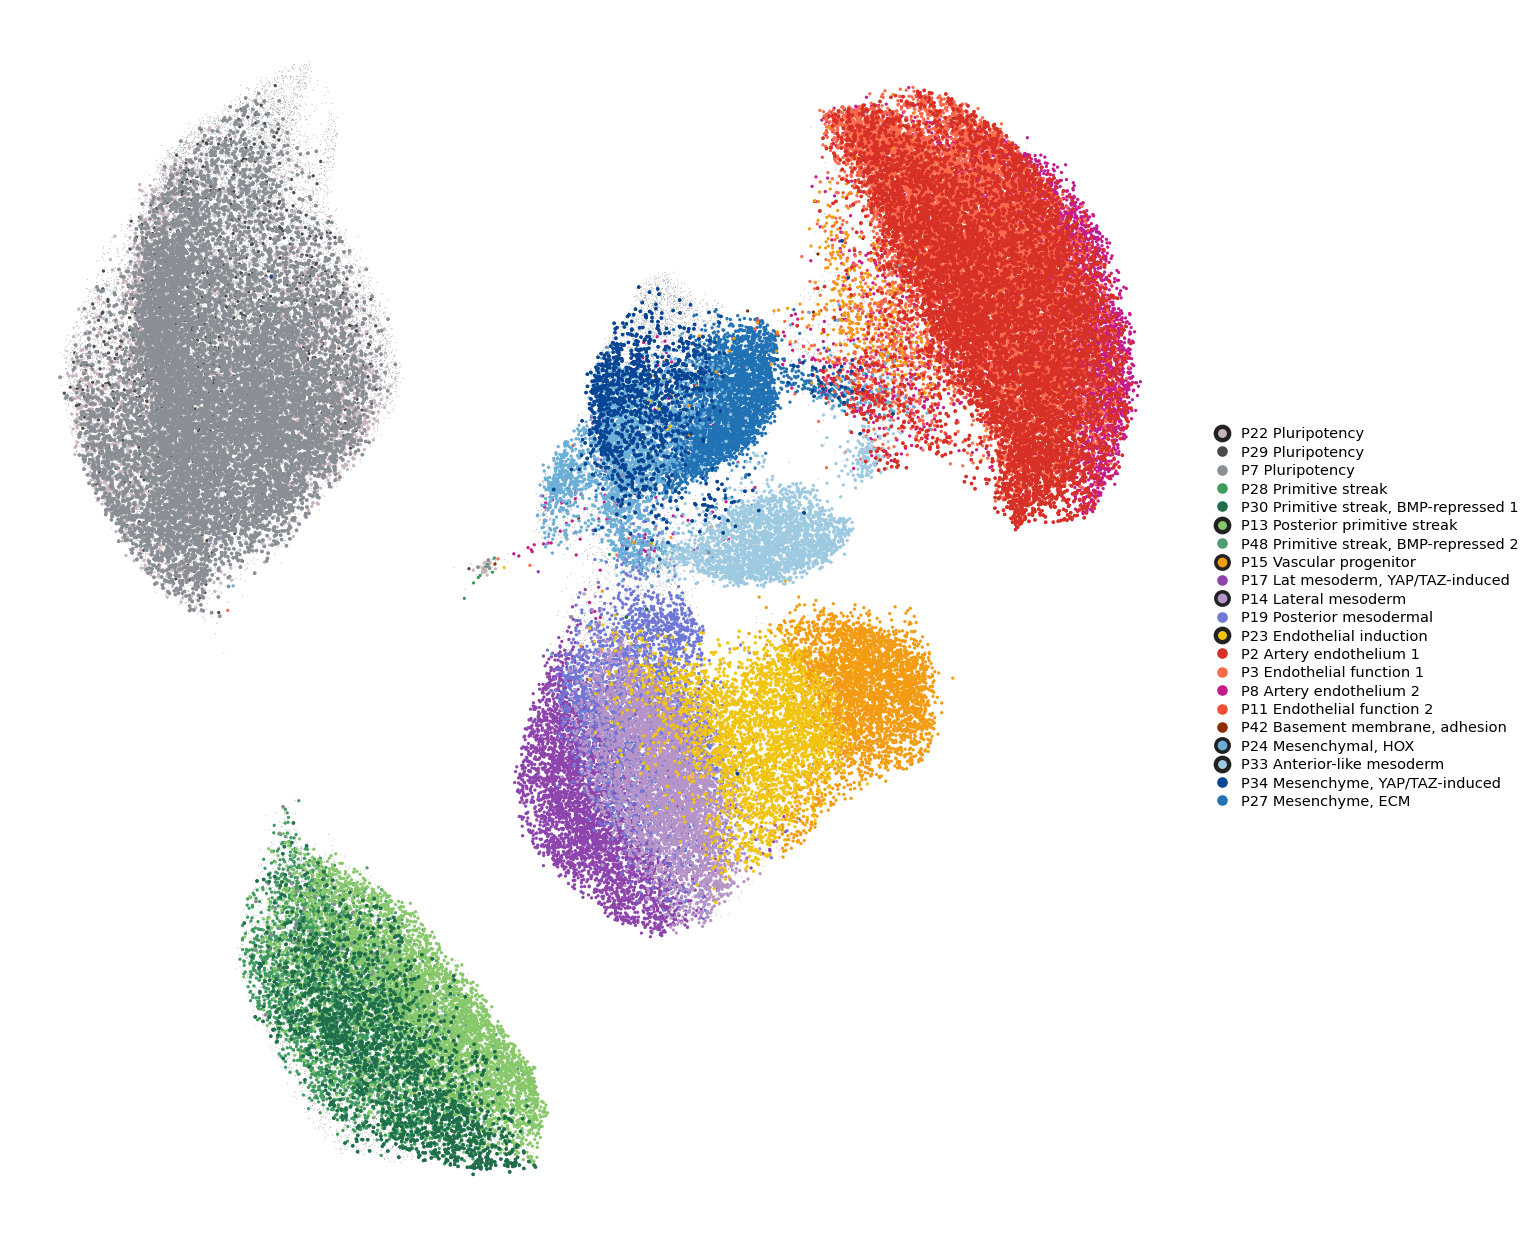

dominant_selected_program  above_0.02_threshold
2                          True                     8499
3                          True                    11993
7                          True                    11183
8                          True                     5097
11                         True                     2072
13                         True                     4298
14                         True                     4129
15                         True                     3964
17                         True                     3919
19                         True                     3363
22                         True                     3951
23                         True                     3145
24                         True                     2770
27                         True                     3705
28                         True                     3617
29                         True                     1262
30                         True         

In [5]:
h5mu_path = get_path(ctx["paths"], "ccperturbseq.cnmf_h5mu")
adata_path = get_path(ctx["paths"], "ccperturbseq.integrated_anndata")
metadata_path = get_path(ctx["paths"], "ccperturbseq.figure1d_program_metadata")
order_path = get_path(ctx["paths"], "ccperturbseq.figure1d_program_order")
fig_d, source_d, programs_d, threshold_d = make_figure_01d(
    h5mu_path,
    adata_path,
    metadata_path,
    order_path,
)
out_d = panel_directory(ctx, "d")
outputs_d = save_matplotlib_figure(
    fig_d,
    out_d,
    "Figure_01d_integrated_program_atlas",
    png_dpi=300,
    pad_inches=0.02,
)
source_d.to_csv(
    out_d / "Figure_01d_cell_program_assignment.csv.gz",
    index=False,
    compression="gzip",
)
write_receipt(
    ctx,
    "d",
    status="SOURCE_VERIFIED_IMPLEMENTATION",
    inputs={
        "h5mu": str(h5mu_path),
        "integrated_anndata": str(adata_path),
        "program_metadata": str(metadata_path),
        "program_order": str(order_path),
    },
    outputs={
        **outputs_d,
        "cell_program_assignment": str(out_d / "Figure_01d_cell_program_assignment.csv.gz"),
    },
    parameters={
        "source_notebook": "programDE/notebooks/per_day_umaps/jesse_umap.ipynb",
        "programs": programs_d,
        "dominant_program_threshold": threshold_d,
        "umap_source": "integrated AnnData X_umap",
        "program_score_source": "cNMF modality in cNMF_50_0_2.h5mu",
        "plotting_backend": "recovered panel-d renderer",
    },
)
display(fig_d)
source_d[["dominant_selected_program", "above_0.02_threshold"]].value_counts().sort_index()
